# Plot treatment+dose multiclass MLP performance
Plots the global treatment+dose classifier's training and held-out test-set performance, from the data saved by `6.train_multiclass_mlp_treatment_dose.ipynb` and `7.evaluate_multiclass_mlp_treatment_dose.ipynb`:

1. Training curve (train/val loss).
2. Top-k accuracy.
3. Per-class F1 score.
4. Confusion matrix.

In [1]:
list_of_packages <- c("ggplot2", "dplyr", "tidyr", "arrow", "RColorBrewer")
for (package in list_of_packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(package, character.only = TRUE, quietly = TRUE, warn.conflicts = FALSE)
        )
    )
}

find_git_root <- function() {
    cwd <- getwd()
    if (dir.exists(file.path(cwd, ".git"))) {
        return(cwd)
    }
    current_path <- cwd
    while (dirname(current_path) != current_path) {
        parent_path <- dirname(current_path)
        if (dir.exists(file.path(parent_path, ".git"))) {
            return(parent_path)
        }
        current_path <- parent_path
    }
    stop("No Git root directory found.")
}

root_dir <- find_git_root()
source(file.path(root_dir, "utils", "r_plot_themes.r"))

module_dir <- file.path(root_dir, "6.treatment_predictive_model")
results_dir <- file.path(module_dir, "model_results")
figures_dir <- file.path(module_dir, "figures")
dir.create(figures_dir, recursive = TRUE, showWarnings = FALSE)

TASK_PREFIX <- "multiclass_mlp_treatment_dose"

## 1. Training curve

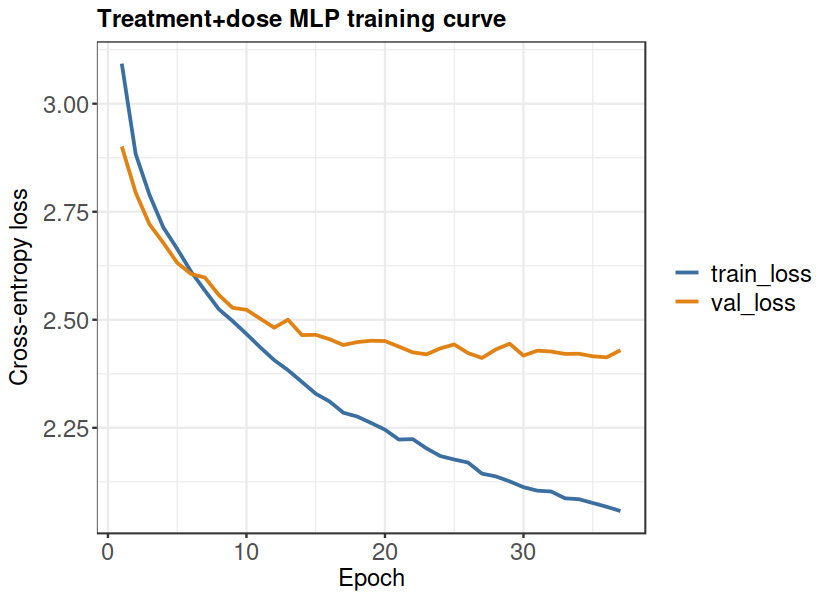

In [2]:
options(repr.plot.width = 7, repr.plot.height = 5)

training_curve_df <- read_parquet(
    file.path(results_dir, paste0(TASK_PREFIX, "_training_curve.parquet"))
) %>%
    pivot_longer(cols = c(train_loss, val_loss), names_to = "split", values_to = "loss")

training_curve_plot <- (
    ggplot(training_curve_df, aes(x = epoch, y = loss, colour = split))
    + geom_line(linewidth = 0.8)
    + scale_colour_manual(values = c(train_loss = "#3B6FA0", val_loss = "#E08214"), name = NULL)
    + labs(x = "Epoch", y = "Cross-entropy loss", title = "Treatment+dose MLP training curve")
    + theme_manuscript(base_size = 14)
)

ggsave(
    file.path(figures_dir, paste0(TASK_PREFIX, "_training_curve.png")),
    training_curve_plot, width = 7, height = 5, dpi = 600, bg = "white"
)
training_curve_plot

## 2. Top-k accuracy

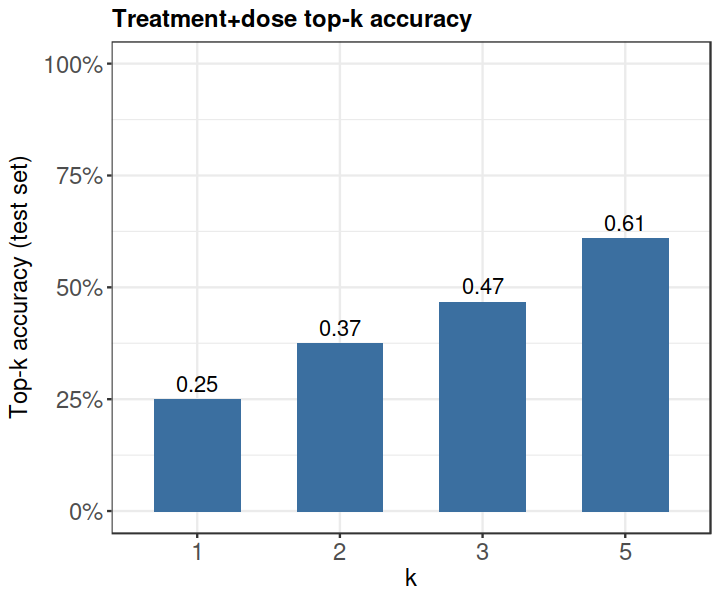

In [3]:
options(repr.plot.width = 6, repr.plot.height = 5)

top_k_df <- read_parquet(
    file.path(results_dir, paste0(TASK_PREFIX, "_top_k_accuracy.parquet"))
) %>%
    mutate(k = factor(k))

top_k_plot <- (
    ggplot(top_k_df, aes(x = k, y = top_k_accuracy))
    + geom_col(fill = "#3B6FA0", width = 0.6)
    + geom_text(aes(label = sprintf("%.2f", top_k_accuracy)), vjust = -0.5, size = 4.5)
    + scale_y_continuous(limits = c(0, 1), labels = scales::percent)
    + labs(x = "k", y = "Top-k accuracy (test set)", title = "Treatment+dose top-k accuracy")
    + theme_manuscript(base_size = 14)
)

ggsave(
    file.path(figures_dir, paste0(TASK_PREFIX, "_top_k_accuracy.png")),
    top_k_plot, width = 6, height = 5, dpi = 600, bg = "white"
)
top_k_plot

## 3. Per-class F1 score

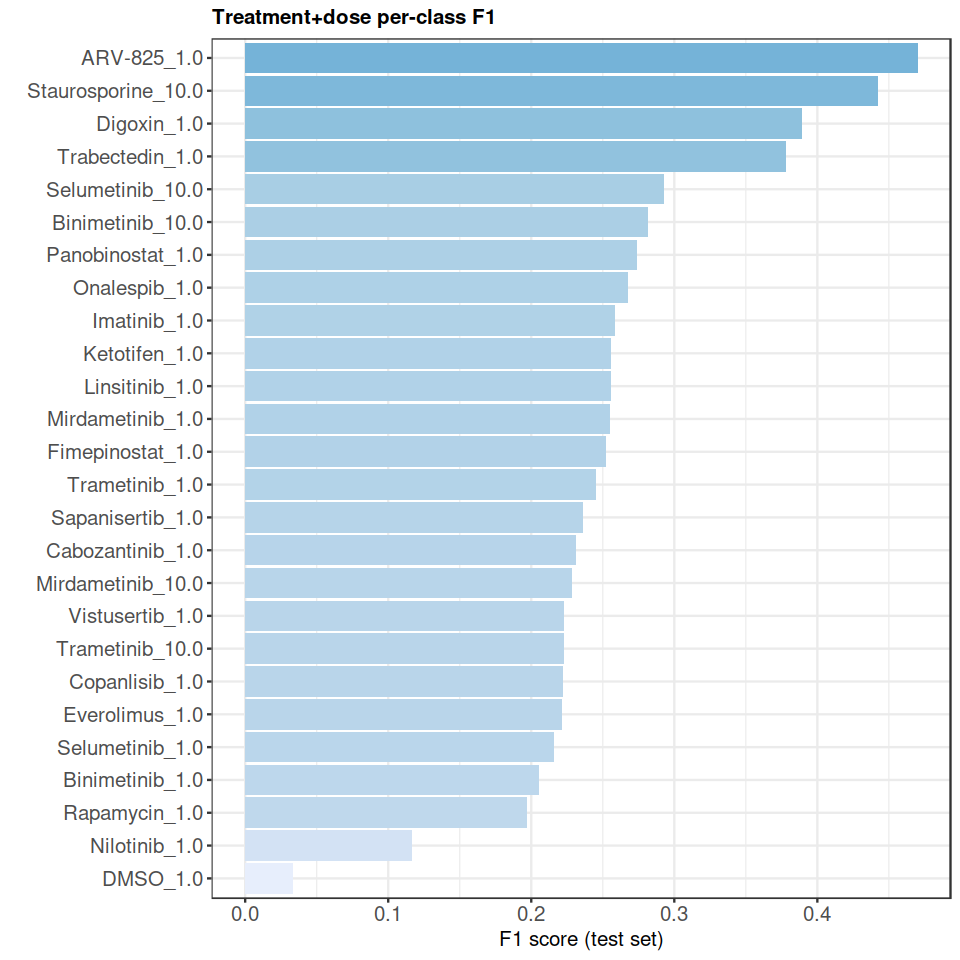

In [4]:
options(repr.plot.width = 8, repr.plot.height = 8)

per_class_df <- read_parquet(
    file.path(results_dir, paste0(TASK_PREFIX, "_classification_report.parquet"))
) %>%
    filter(!Metadata_class %in% c("macro avg", "weighted avg")) %>%
    mutate(Metadata_class = reorder(Metadata_class, `f1-score`))

per_class_f1_plot <- (
    ggplot(per_class_df, aes(x = Metadata_class, y = `f1-score`, fill = `f1-score`))
    + geom_col()
    + coord_flip()
    + scale_fill_distiller(palette = "Blues", direction = 1, limits = c(0, 1), guide = "none")
    + labs(x = NULL, y = "F1 score (test set)", title = "Treatment+dose per-class F1")
    + theme_manuscript(base_size = 12)
)

ggsave(
    file.path(figures_dir, paste0(TASK_PREFIX, "_per_class_f1.png")),
    per_class_f1_plot, width = 8, height = 8, dpi = 600, bg = "white"
)
per_class_f1_plot

## 4. Confusion matrix
Computed directly from the saved true/predicted labels (row-normalized).

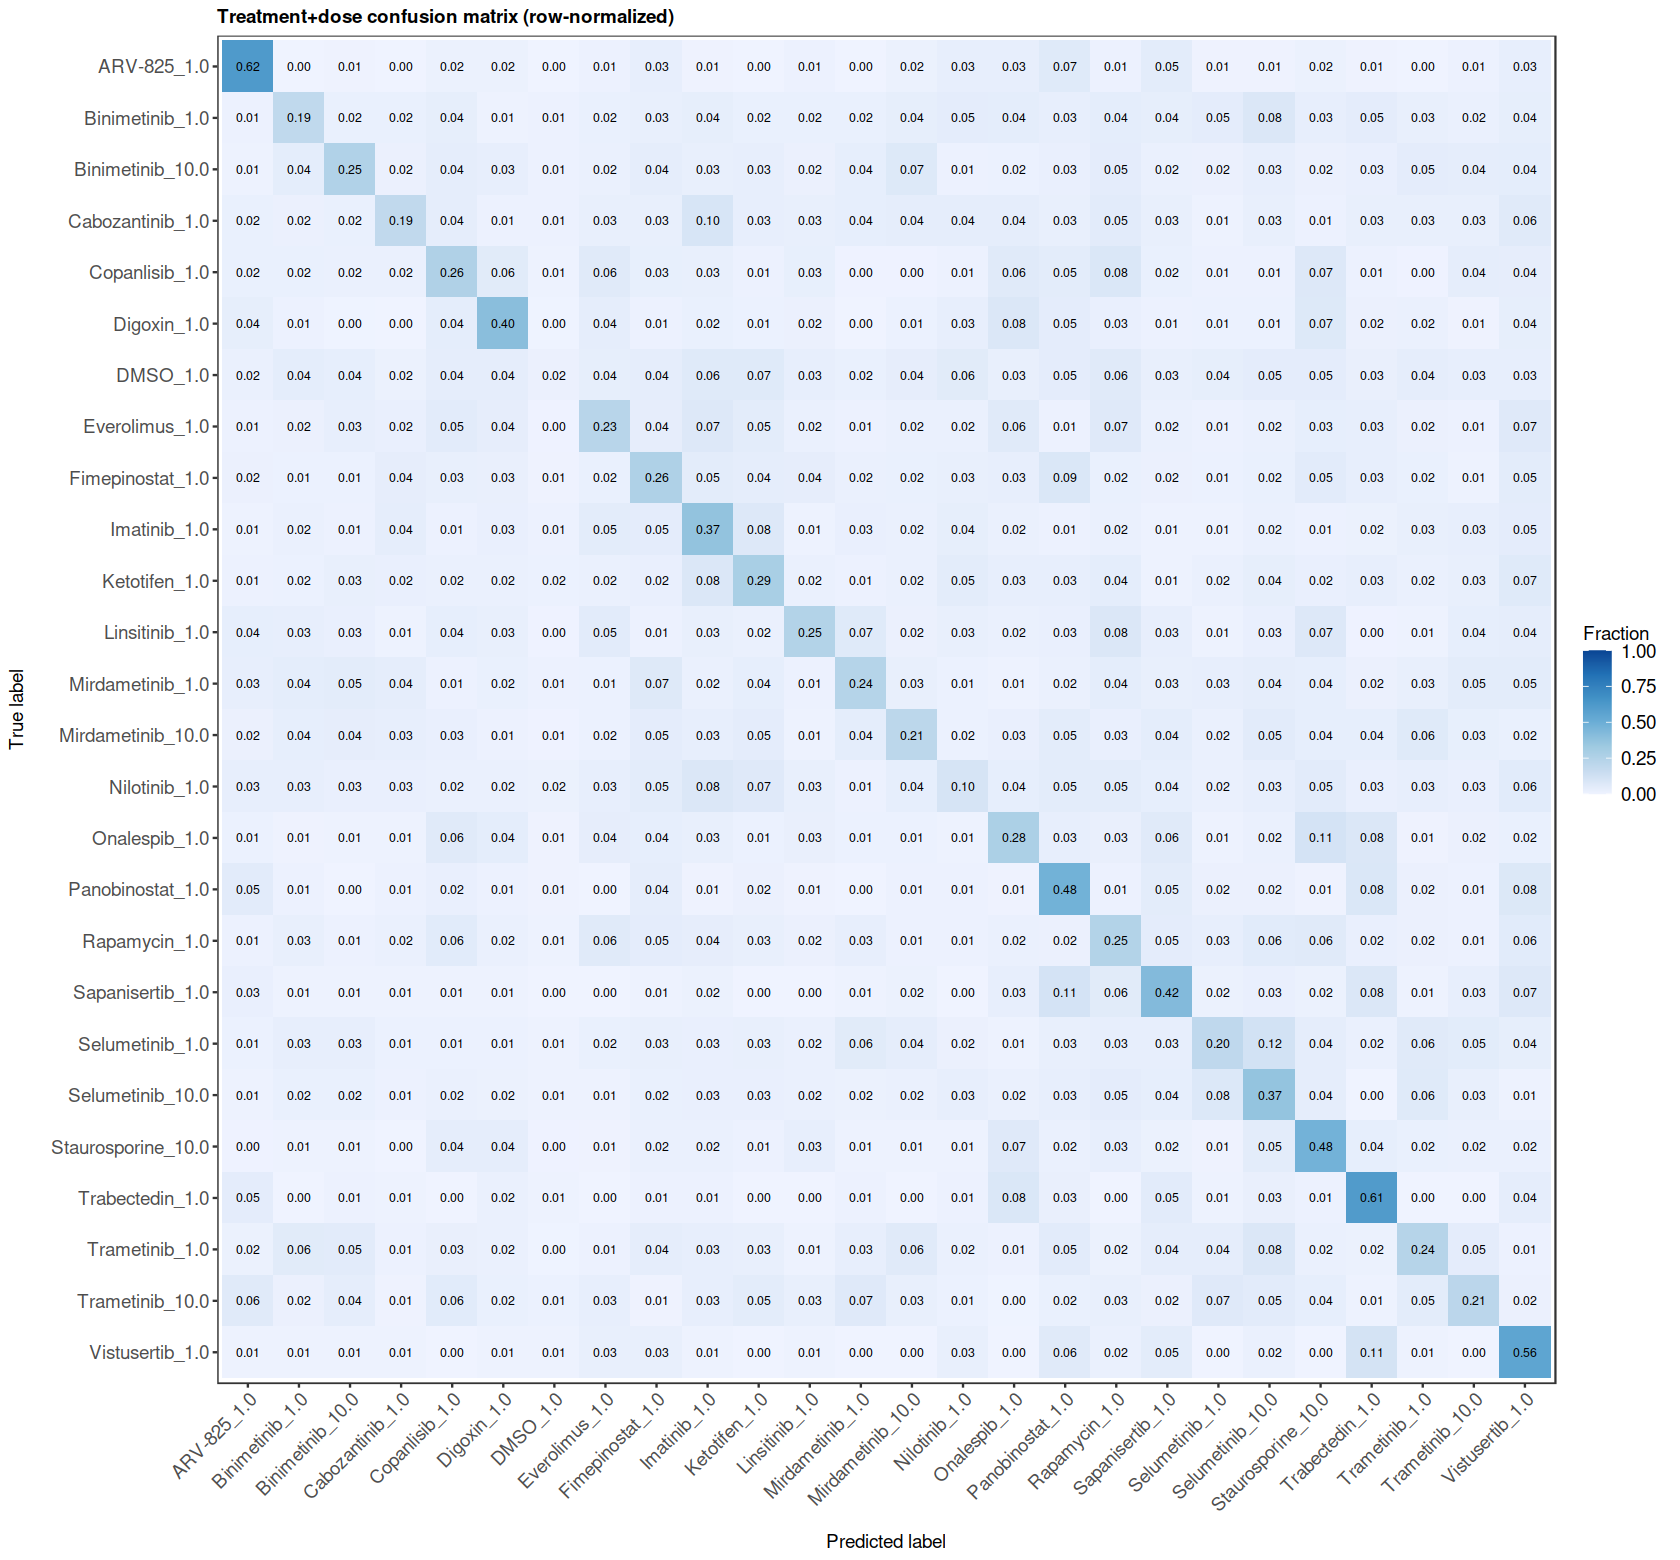

In [5]:
options(repr.plot.width = 14, repr.plot.height = 13)

test_predictions_df <- read_parquet(
    file.path(results_dir, paste0(TASK_PREFIX, "_test_predictions.parquet"))
)
class_levels <- sort(unique(c(
    test_predictions_df$Metadata_true_label, test_predictions_df$Metadata_predicted_label
)))

confusion_df <- test_predictions_df %>%
    count(Metadata_true_label, Metadata_predicted_label, name = "n") %>%
    tidyr::complete(
        Metadata_true_label = class_levels, Metadata_predicted_label = class_levels,
        fill = list(n = 0)
    ) %>%
    group_by(Metadata_true_label) %>%
    mutate(fraction = n / sum(n)) %>%
    ungroup() %>%
    mutate(
        Metadata_true_label = factor(Metadata_true_label, levels = class_levels),
        Metadata_predicted_label = factor(Metadata_predicted_label, levels = class_levels)
    )

confusion_matrix_plot <- (
    ggplot(confusion_df, aes(x = Metadata_predicted_label, y = Metadata_true_label, fill = fraction))
    + geom_tile()
    + geom_text(aes(label = sprintf("%.2f", fraction)), size = 2.5)
    + scale_fill_distiller(palette = "Blues", direction = 1, limits = c(0, 1), name = "Fraction")
    + scale_y_discrete(limits = rev(class_levels))
    + labs(
        x = "Predicted label", y = "True label",
        title = "Treatment+dose confusion matrix (row-normalized)"
    )
    + theme_manuscript(base_size = 11, x_text = "angled")
    + theme(panel.grid = element_blank())
)

ggsave(
    file.path(figures_dir, paste0(TASK_PREFIX, "_confusion_matrix.png")),
    confusion_matrix_plot, width = 14, height = 13, dpi = 600, bg = "white"
)
confusion_matrix_plot